# MobileNetV2 para Cassava

**Asignatura:** Inteligencia Artificial  
**Proyecto:** Clasificación de enfermedades foliares de yuca  
**Grupo:** 1 · **Modelo asignado:** MobileNetV2

## Objetivo
Entrenar MobileNetV2 con la **misma preparación de datos** de `Preparacion_Cassava.ipynb` (224 × 224, relleno, lotes de 32, particiones
originales) y comparar tres corridas:

1. **Sin ponderación:** base MobileNetV2 congelada; 5 épocas, Adam con LR 0,001.
2. **Ponderación moderada:** nueva MobileNetV2 desde ImageNet, con pesos de clase moderados.
3. **Ajuste fino:** continuar el mejor modelo de las dos corridas anteriores y descongelar
   el 30 % superior de la base (exceptuando BatchNormalization).

## Preparación de los datos
Se ejecutan los pasos de `Preparacion_Cassava.ipynb` sin cambios 

In [3]:
# PASO 1: Importación y verificación de librerías
import sys
print("Python del kernel:", sys.executable)
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import numpy as np

# Mostrar versiones utilizadas
print("TensorFlow:", tf.__version__)
print("TensorFlow Datasets:", tfds.__version__)
# Comprobar si existe una GPU disponible
print("GPU disponible:", tf.config.list_physical_devices("GPU"))
print("\nLibrerías importadas correctamente.")

Python del kernel: c:\Users\Laddy\entrenamiento\BeanCass-AI\.venv\Scripts\python.exe
TensorFlow: 2.21.0
TensorFlow Datasets: 4.9.10
GPU disponible: []

Librerías importadas correctamente.


In [4]:
# PASO 2: Carga del dataset Cassava
# Descargar el dataset y cargar sus tres particiones originales
(ds_train, ds_val, ds_test), info = tfds.load(
    "cassava",
    split=["train", "validation", "test"],
    with_info=True,
    as_supervised=False,
    shuffle_files=False
)
# Confirmar que el dataset fue cargado correctamente
print("Cassava descargado y particiones cargadas correctamente.")

Cassava descargado y particiones cargadas correctamente.


In [6]:
# PASO 3: Análisis de metadatos del dataset Cassava
# Mostrar información general del dataset
print("Nombre del dataset:", info.name)
print("Versión:", info.version)

# Mostrar la cantidad de imágenes por conjunto
print("\n--- DISTRIBUCIÓN DE DATOS ---")
total = 0

for nombre, datos in info.splits.items():
    print(f"{nombre}: {datos.num_examples} imágenes")
    total += datos.num_examples

print("Total de imágenes:", total)

# Mostrar la cantidad de clases y sus etiquetas
print("\n--- CLASES Y ETIQUETAS ---")
clases = info.features["label"].names

print("Número de clases:", len(clases))

for codigo, nombre in enumerate(clases):
    print(f"Etiqueta {codigo}: {nombre}")

# Mostrar las características de las imágenes
print("\n--- CARACTERÍSTICAS DE LAS IMÁGENES ---")
print("Dimensiones:", info.features["image"].shape)
print("Tipo de dato:", info.features["image"].np_dtype)
print("Características disponibles:", list(info.features.keys()))

Nombre del dataset: cassava
Versión: 0.1.0

--- DISTRIBUCIÓN DE DATOS ---
train: 5656 imágenes
test: 1885 imágenes
validation: 1889 imágenes
Total de imágenes: 9430

--- CLASES Y ETIQUETAS ---
Número de clases: 5
Etiqueta 0: cbb
Etiqueta 1: cbsd
Etiqueta 2: cgm
Etiqueta 3: cmd
Etiqueta 4: healthy

--- CARACTERÍSTICAS DE LAS IMÁGENES ---
Dimensiones: (None, None, 3)
Tipo de dato: <class 'numpy.uint8'>
Características disponibles: ['image', 'image/filename', 'label']


In [7]:
# PASO 5: Preparación de datos para el entrenamiento
# Definir parámetros generales
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# Función para redimensionar cada imagen y conservar su etiqueta
def preparar_imagen(registro):
    imagen = tf.image.resize_with_pad(
        registro["image"],
        IMG_SIZE[0],
        IMG_SIZE[1],
        antialias=True,)
    # Mantener los píxeles float32 en el rango común de 0 a 255.
    imagen = tf.clip_by_value(imagen, 0.0, 255.0)
    return imagen, registro["label"]
# Función para organizar los datos en lotes
def preparar_dataset(dataset, entrenamiento=False):

    # Mezclar únicamente las imágenes de entrenamiento
    if entrenamiento:
        dataset = dataset.shuffle(1000, seed=42)
    # Redimensionar las imágenes
    dataset = dataset.map(
        preparar_imagen, num_parallel_calls=AUTOTUNE
    )
    # Agrupar las imágenes y optimizar su lectura
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)
    return dataset
# Preparar Train, Validation y Test
train_preparado = preparar_dataset(ds_train, entrenamiento=True)
val_preparado = preparar_dataset(ds_val)
test_preparado = preparar_dataset(ds_test)

print("Datos preparados correctamente.")

# Comprobar las dimensiones de un lote
for imagenes, etiquetas in train_preparado.take(1):
    print("Dimensiones del lote:", imagenes.shape)
    print("Dimensiones de etiquetas:", etiquetas.shape)
    print("Tipo de dato:", imagenes.dtype)

Datos preparados correctamente.
Dimensiones del lote: (32, 224, 224, 3)
Dimensiones de etiquetas: (32,)
Tipo de dato: <dtype: 'float32'>


In [8]:
# PASO 8: Verificar las entradas antes de entrenar la CNN propia
for nombre, dataset in [
    ("Train", train_preparado),
    ("Validation", val_preparado),
]:
    imagenes, etiquetas = next(iter(dataset))

    tf.debugging.assert_shapes([
        (imagenes, ("lote", 224, 224, 3)),
        (etiquetas, ("lote",)),
    ])
    tf.debugging.assert_all_finite(imagenes, f"{nombre}: píxeles no finitos")
    tf.debugging.assert_greater_equal(imagenes, 0.0)
    tf.debugging.assert_less_equal(imagenes, 255.0)
    tf.debugging.assert_greater_equal(etiquetas, tf.cast(0, etiquetas.dtype))
    tf.debugging.assert_less(
        etiquetas, tf.cast(len(clases), etiquetas.dtype)
    )

    print(
        f"{nombre} | imágenes: {imagenes.shape} | "
        f"etiquetas: {etiquetas.shape} | "
        f"píxeles: {float(tf.reduce_min(imagenes)):.1f} a "
        f"{float(tf.reduce_max(imagenes)):.1f}"
    )
print("Los lotes de Train y Validation pasaron la verificación.")

Train | imágenes: (32, 224, 224, 3) | etiquetas: (32,) | píxeles: 0.0 a 255.0
Validation | imágenes: (32, 224, 224, 3) | etiquetas: (32,) | píxeles: 0.0 a 255.0
Los lotes de Train y Validation pasaron la verificación.


## Funciones de entrenamiento y evaluación

Se entrenará una base preentrenada en ImageNet con
`Dropout(0.2)` y una salida `softmax` para las cinco clases de Cassava.

MobileNetV2 requiere transformar los píxeles de 0–255 a **-1 a 1**.
Esta normalización se integra en el propio modelo mediante `Rescaling(1 / 127.5, offset=-1)`,


In [9]:
# PASO 9: Funciones comunes para entrenar, guardar y evaluar MobileNetV2
import csv
import json
import time
from datetime import datetime
from pathlib import Path
from tensorflow import keras
from tensorflow.keras import layers

PRUEBA_RAPIDA = False  # True: verifica el funcionamiento con solo 2 lotes (NO válido como resultado final)

carpeta_actual = Path.cwd()
carpeta_dataset = (
    carpeta_actual if carpeta_actual.name.lower() == "cassava"
    else carpeta_actual / "cassava"
)
if not (carpeta_dataset / "Preparacion_Cassava.ipynb").is_file():
    raise FileNotFoundError(
        "Abre BeanCass-AI en VS Code y ejecuta desde la carpeta raíz o desde cassava/."
    )

carpeta_resultados = carpeta_dataset / "resultados" / "mobilenetv2"
carpeta_resultados.mkdir(parents=True, exist_ok=True)


def construir_mobilenetv2(n_clases, nombre):
    """MobileNetV2 preentrenada en ImageNet con normalización y clasificador nuevo."""
    keras.utils.set_random_seed(42)
    base = keras.applications.MobileNetV2(
        include_top=False,
        weights="imagenet",
        input_shape=(*IMG_SIZE, 3),
        pooling="avg",
    )
    # Durante la fase inicial solo aprende la nueva capa de salida.
    base.trainable = False

    entrada = keras.Input(shape=(*IMG_SIZE, 3), name="imagen")
    # MobileNetV2 espera [-1, 1]; los datasets entregan imágenes en [0, 255].
    x = layers.Rescaling(1.0 / 127.5, offset=-1.0, name="normalizacion_mobilenetv2")(entrada)
    # training=False mantiene estables las estadísticas de BatchNormalization incluso
    # cuando más adelante descongelemos algunas capas para el ajuste fino.
    caracteristicas = base(x, training=False)
    x = layers.Dropout(0.2, name="dropout")(caracteristicas)
    salida = layers.Dense(
        n_clases, activation="softmax", name=f"clasificacion_{nombre}"
    )(x)
    modelo = keras.Model(entrada, salida, name=f"mobilenetv2_{nombre}")
    return modelo, base


def compilar(modelo, lr):
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"],
    )


def entrenar(modelo, prefijo, epocas, pesos_clase=None, datos_train=None):
    """Entrena y guarda modelo, CSV y tiempo en su propia carpeta."""
    datos_train = train_preparado if datos_train is None else datos_train
    datos_val = val_preparado
    if PRUEBA_RAPIDA:
        print("ATENCIÓN: PRUEBA_RAPIDA activa. No usar estas métricas en el informe.")
        datos_train, datos_val, epocas = datos_train.take(2), datos_val.take(1), 1

    nombre_corrida = datetime.now().strftime(f"{prefijo}_%Y%m%d_%H%M%S_%f")
    carpeta = carpeta_resultados / nombre_corrida
    carpeta.mkdir(parents=True, exist_ok=False)
    ruta_modelo = carpeta / "mejor_modelo.keras"
    print("Resultados de esta corrida en:", carpeta.resolve())

    total_parametros = int(modelo.count_params())
    entrenables = int(sum(np.prod(p.shape) for p in modelo.trainable_weights))
    print(f"Parámetros totales: {total_parametros:,} · entrenables: {entrenables:,}")

    inicio = time.perf_counter()
    historial = modelo.fit(
        datos_train,
        validation_data=datos_val,
        epochs=epocas,
        class_weight=pesos_clase,
        callbacks=[
            # Registrar las métricas de cada época para el informe.
            keras.callbacks.CSVLogger(str(carpeta / "historial.csv")),
            # Conservar el mejor modelo por pérdida de validación.
            keras.callbacks.ModelCheckpoint(
                filepath=str(ruta_modelo), monitor="val_loss",
                mode="min", save_best_only=True,
            ),
            keras.callbacks.EarlyStopping(
                monitor="val_loss", mode="min", patience=2,
                restore_best_weights=True,
            ),
        ],
        verbose=2,
    )
    tiempo = round(time.perf_counter() - inicio, 2)
    detalles = {
        "arquitectura": "MobileNetV2",
        "corrida": nombre_corrida,
        "dataset": "cassava",
        "version_tfds": str(info.version),
        "epocas_configuradas": epocas,
        "epocas_ejecutadas": len(historial.history.get("loss", [])),
        "batch_size": BATCH_SIZE,
        "tamano_imagen": IMG_SIZE,
        "optimizador": "Adam",
        "learning_rate": float(keras.backend.get_value(modelo.optimizer.learning_rate)),
        "loss": "SparseCategoricalCrossentropy",
        "pesos_clase": pesos_clase,
        "tiempo_entrenamiento_segundos": tiempo,
        "parametros_totales": total_parametros,
        "parametros_entrenables": entrenables,
        "prueba_rapida": PRUEBA_RAPIDA,
    }
    (carpeta / "entrenamiento.json").write_text(
        json.dumps(detalles, indent=2, ensure_ascii=False), encoding="utf-8"
    )
    print(f"Entrenamiento realizado en {tiempo:.2f} segundos")
    print("Mejor modelo guardado:", ruta_modelo.is_file())
    return carpeta


def evaluar(carpeta, titulo):
    """Matriz de confusión, métricas por clase y curvas en Validation."""
    modelo = keras.models.load_model(str(carpeta / "mejor_modelo.keras"), compile=False)
    nombres = list(clases)
    matriz = np.zeros((len(nombres), len(nombres)), dtype=int)
    datos_val = val_preparado.take(1) if PRUEBA_RAPIDA else val_preparado
    for imagenes, etiquetas in datos_val:
        predicciones = np.argmax(modelo(imagenes, training=False).numpy(), axis=1)
        np.add.at(matriz, (etiquetas.numpy(), predicciones), 1)

    aciertos = matriz.diagonal()
    reales = matriz.sum(axis=1)
    predichas = matriz.sum(axis=0)
    precision = aciertos / np.maximum(predichas, 1)
    recall = aciertos / np.maximum(reales, 1)
    f1 = 2 * aciertos / np.maximum(reales + predichas, 1)
    exactitud = aciertos.sum() / max(reales.sum(), 1)

    print("Orden de clases:", nombres)
    print("Matriz de confusión (filas reales, columnas predichas):")
    print(matriz)
    print("\nClase              Aciertos   Precisión   Recall      F1")
    for i, clase in enumerate(nombres):
        print(f"{clase:<18} {aciertos[i]:>4}/{reales[i]:<5}"
              f" {precision[i]:>9.2%} {recall[i]:>9.2%} {f1[i]:>8.4f}")
    print(f"\nExactitud en Validation: {exactitud:.2%}")
    print(f"F1 macro: {f1.mean():.4f}")

    # Archivo de resultados, con estructura similar al notebook EfficientNetB0.
    resumen = {
        "corrida": carpeta.name,
        "exactitud_validation": round(float(exactitud), 4),
        "f1_macro_validation": round(float(f1.mean()), 4),
        "precision_por_clase": {c: round(float(v), 4) for c, v in zip(nombres, precision)},
        "f1_por_clase": {c: round(float(v), 4) for c, v in zip(nombres, f1)},
        "recall_por_clase": {c: round(float(v), 4) for c, v in zip(nombres, recall)},
        "matriz_confusion": matriz.tolist(),
    }
    ruta_detalles = carpeta / "entrenamiento.json"
    if ruta_detalles.is_file():
        resumen.update(json.loads(ruta_detalles.read_text(encoding="utf-8")))
    (carpeta / "metricas_validation.json").write_text(
        json.dumps(resumen, indent=2, ensure_ascii=False), encoding="utf-8"
    )

    # Matriz de confusión en porcentaje por clase real.
    porcentajes = 100 * matriz / np.maximum(matriz.sum(axis=1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(7.5, 5.5), layout="constrained")
    imagen = ax.imshow(porcentajes, cmap="Blues", vmin=0, vmax=100)
    fig.colorbar(imagen, ax=ax, label="Porcentaje de la clase real")
    ax.set_xticks(range(len(nombres)), labels=nombres, rotation=20)
    ax.set_yticks(range(len(nombres)), labels=nombres)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.set_title(f"{titulo}\nValidación · F1 macro {f1.mean():.4f}")
    for fila, columna in np.ndindex(matriz.shape):
        color = "white" if porcentajes[fila, columna] > 55 else "black"
        ax.text(columna, fila, f"{matriz[fila, columna]}\n{porcentajes[fila, columna]:.0f}%",
                ha="center", va="center", color=color, fontsize=9)
    fig.savefig(carpeta / "matriz_confusion_validation.png", dpi=150)
    plt.show()

    # Curvas tomadas del historial.csv de la corrida.
    with (carpeta / "historial.csv").open(encoding="utf-8", newline="") as archivo:
        registros = list(csv.DictReader(archivo))
    epocas = [int(fila["epoch"]) + 1 for fila in registros]
    mejor = min(registros, key=lambda fila: float(fila["val_loss"]))
    fig, ejes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
    fig.suptitle(titulo)
    for eje, metrica, nombre_metrica in [
        (ejes[0], "accuracy", "Exactitud"), (ejes[1], "loss", "Pérdida")
    ]:
        eje.plot(epocas, [float(f[metrica]) for f in registros], marker="o", label="Train")
        eje.plot(epocas, [float(f[f"val_{metrica}"]) for f in registros], marker="o", label="Validation")
        eje.axvline(int(mejor["epoch"]) + 1, color="gray", linestyle="--", label="Mejor época")
        eje.set_title(nombre_metrica)
        eje.set_xlabel("Época")
        eje.set_xticks(epocas)
        eje.grid(alpha=0.3)
        eje.legend()
    ejes[0].set_ylim(0, 1)
    fig.savefig(carpeta / "curvas_entrenamiento.png", dpi=150)
    plt.show()
    return resumen


def ajuste_fino(carpeta_origen, prefijo, epocas, pesos_clase=None, fraccion=0.30):
    """Continúa el mejor modelo congelado y descongela la parte alta de MobileNetV2."""
    modelo = keras.models.load_model(str(carpeta_origen / "mejor_modelo.keras"), compile=False)
    base = next(capa for capa in modelo.layers if isinstance(capa, keras.Model))
    base.trainable = True
    corte = int(len(base.layers) * (1 - fraccion))
    for i, capa in enumerate(base.layers):
        # Evitar alterar las estadísticas de BatchNormalization de ImageNet.
        capa.trainable = i >= corte and not isinstance(capa, layers.BatchNormalization)
    entrenables = sum(capa.trainable for capa in base.layers)
    print(f"Capas de la base entrenables en fine-tuning: {entrenables} de {len(base.layers)}")
    # Compilar otra vez tras modificar qué capas son entrenables.
    compilar(modelo, 1e-4)
    return entrenar(modelo, prefijo, epocas, pesos_clase)

print("Funciones listas. Resultados en:", carpeta_resultados.resolve())

Funciones listas. Resultados en: C:\Users\Laddy\entrenamiento\BeanCass-AI\cassava\resultados\mobilenetv2


## Corrida 1 · MobileNetV2 sin ponderación

In [ ]:
# Corrida 1: base congelada, sin ponderación, 5 épocas y Adam con lr = 0,001
modelo, base = construir_mobilenetv2(len(clases), "cassava")
compilar(modelo, 1e-3)
print(f"Parámetros totales: {modelo.count_params():,} · entrenables: "
      f"{sum(int(np.prod(p.shape)) for p in modelo.trainable_weights):,}")
carpeta_sin_ponderacion = entrenar(modelo, "corrida", epocas=5)

Parámetros totales: 2,264,389 · entrenables: 6,405
Resultados de esta corrida en: C:\Users\Laddy\entrenamiento\BeanCass-AI\cassava\resultados\mobilenetv2\corrida_20261117_041049_112297
Parámetros totales: 2,264,389 · entrenables: 6,405
Epoch 1/5
177/177 - 91s - 516ms/step - accuracy: 0.6008 - loss: 1.0596 - val_accuracy: 0.7163 - val_loss: 0.7902
Epoch 2/5
177/177 - 85s - 482ms/step - accuracy: 0.7070 - loss: 0.7953 - val_accuracy: 0.7337 - val_loss: 0.7443
Epoch 3/5
177/177 - 82s - 463ms/step - accuracy: 0.7272 - loss: 0.7362 - val_accuracy: 0.7544 - val_loss: 0.6976
Epoch 4/5
177/177 - 81s - 460ms/step - accuracy: 0.7424 - loss: 0.6948 - val_accuracy: 0.7634 - val_loss: 0.6793
Epoch 5/5
177/177 - 131s - 739ms/step - accuracy: 0.7514 - loss: 0.6727 - val_accuracy: 0.7560 - val_loss: 0.6893
Entrenamiento realizado en 471.04 segundos
Mejor modelo guardado: True


In [ ]:
resumen_1 = evaluar(carpeta_sin_ponderacion, "MobileNetV2 sin ponderación · Cassava")

## Corrida 2 · Ponderación moderada de clases

En la partición Train, `cmd` dispone de 2658 imágenes y `healthy` de 316.
**Validation y Test permanecen intactos.**

In [12]:
# Corrida 2: se inicializa una nueva MobileNetV2 con pesos de clase moderados
# Conteos de Train documentados por el equipo con Cassava de TFDS.
conteos_train = {"cbb": 466, "cbsd": 1443, "cgm": 773, "cmd": 2658, "healthy": 316}
assert set(conteos_train) == set(clases), "Las clases cargadas no coinciden con el conteo documentado."
assert sum(conteos_train.values()) == info.splits["train"].num_examples, (
    "Cambió el tamaño de Train: revisa los conteos de las clases antes de usar class_weight."
)
total_train = sum(conteos_train.values())
pesos_originales = {
    indice: total_train / (len(clases) * conteos_train[nombre])
    for indice, nombre in enumerate(clases)
}
pesos_moderados = {
    indice: (1.0 + peso) / 2.0 for indice, peso in pesos_originales.items()
}
for indice, nombre in enumerate(clases):
    print(f"{nombre}: {conteos_train[nombre]} fotos, peso {pesos_moderados[indice]:.2f}")

modelo, base = construir_mobilenetv2(len(clases), "cassava")
compilar(modelo, 1e-3)
carpeta_moderada = entrenar(modelo, "ponderada_moderada", epocas=5, pesos_clase=pesos_moderados)

cbb: 466 fotos, peso 1.71
cbsd: 1443 fotos, peso 0.89
cgm: 773 fotos, peso 1.23
cmd: 2658 fotos, peso 0.71
healthy: 316 fotos, peso 2.29
Resultados de esta corrida en: C:\Users\Laddy\entrenamiento\BeanCass-AI\cassava\resultados\mobilenetv2\ponderada_moderada_20261117_193118_439616
Parámetros totales: 2,264,389 · entrenables: 6,405
Epoch 1/5
177/177 - 91s - 513ms/step - accuracy: 0.5702 - loss: 1.1936 - val_accuracy: 0.6596 - val_loss: 0.8752
Epoch 2/5
177/177 - 82s - 465ms/step - accuracy: 0.6849 - loss: 0.9069 - val_accuracy: 0.7454 - val_loss: 0.7438
Epoch 3/5
177/177 - 82s - 462ms/step - accuracy: 0.7192 - loss: 0.8304 - val_accuracy: 0.7390 - val_loss: 0.7482
Epoch 4/5
177/177 - 82s - 464ms/step - accuracy: 0.7369 - loss: 0.7850 - val_accuracy: 0.7470 - val_loss: 0.7206
Epoch 5/5
177/177 - 1283s - 7s/step - accuracy: 0.7463 - loss: 0.7531 - val_accuracy: 0.7517 - val_loss: 0.7026
Entrenamiento realizado en 1619.56 segundos
Mejor modelo guardado: True


Orden de clases: ['cbb', 'cbsd', 'cgm', 'cmd', 'healthy']
Matriz de confusión (filas reales, columnas predichas):
[[ 88  37   8  16   7]
 [ 39 329  14  76  24]
 [ 10  14 152  65  17]
 [ 11  44  41 767  24]
 [  2   9   2   9  84]]

Clase              Aciertos   Precisión   Recall      F1
cbb                  88/156      58.67%    56.41%   0.5752
cbsd                329/482      75.98%    68.26%   0.7191
cgm                 152/258      70.05%    58.91%   0.6400
cmd                 767/887      82.21%    86.47%   0.8429
healthy              84/106      53.85%    79.25%   0.6412

Exactitud en Validation: 75.17%
F1 macro: 0.6837


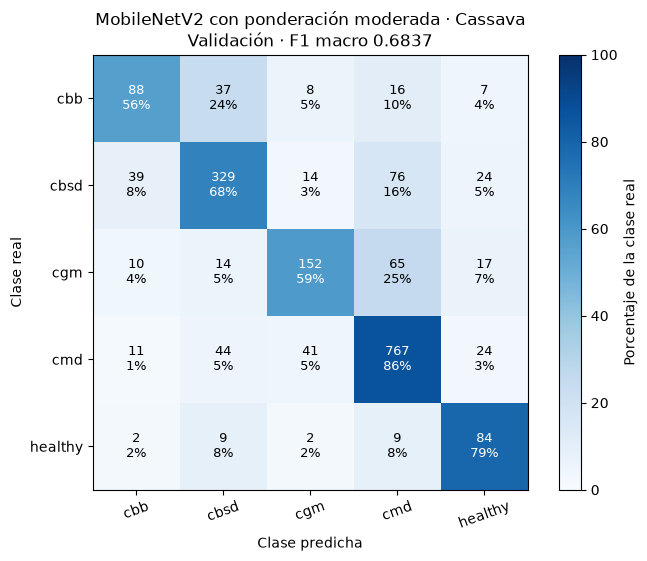

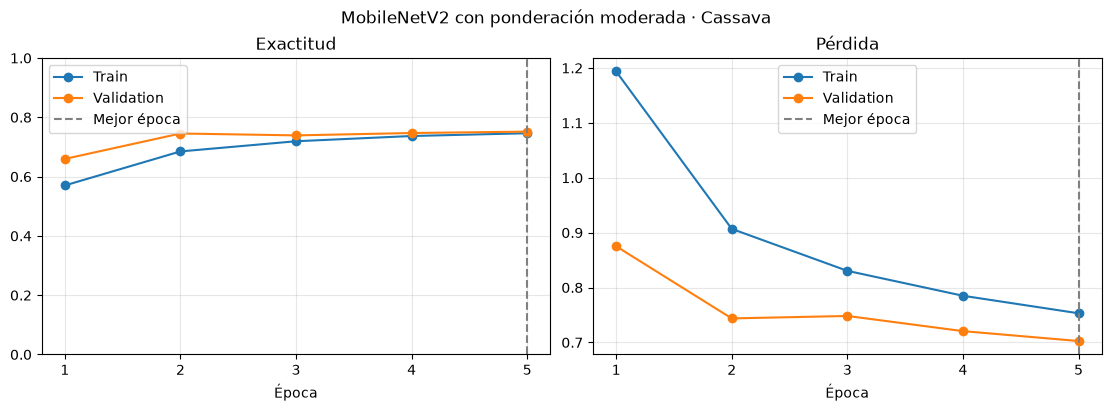

In [14]:
resumen_2 = evaluar(carpeta_moderada, "MobileNetV2 con ponderación moderada · Cassava")

In [11]:
from pathlib import Path
import json

# Carpeta donde están guardados los entrenamientos
raiz = carpeta_resultados

# Primera prueba: sin ponderación
carpeta_sin_ponderacion = raiz / "corrida_20261117_041049_112297"

# Segunda prueba: con ponderación
carpeta_moderada = raiz / "ponderada_moderada_20261117_193118_439616"

# Recuperar resúmenes guardados
resumen_1 = json.loads(
    (carpeta_sin_ponderacion / "metricas_validation.json")
    .read_text(encoding="utf-8")
)

resumen_2 = json.loads(
    (carpeta_moderada / "metricas_validation.json")
    .read_text(encoding="utf-8")
)

print("F1 primera prueba:", resumen_1["f1_macro_validation"])
print("F1 segunda prueba:", resumen_2["f1_macro_validation"])

F1 primera prueba: 0.6942
F1 segunda prueba: 0.6837


## Corrida 3 · Ajuste fino (fine-tuning)

Se carga `mejor_modelo.keras` de la corrida congelada que logró mayor **F1 macro**
en Validation. Se descongela el 30 % superior de MobileNetV2, dejando congeladas
las capas `BatchNormalization`, y se entrena con un learning rate menor (`0.0001`).

**Esta tercera corrida no empieza de cero**: aprovecha los pesos del entrenamiento
anterior. El llamado a la base se mantiene con `training=False` para conservar
las estadísticas de BatchNormalization. 

In [18]:
# Corrida 3: ajuste fino desde la mejor de las dos corridas congeladas
mejor_congelada = max(
    [(resumen_1, carpeta_sin_ponderacion), (resumen_2, carpeta_moderada)],
    key=lambda par: par[0]["f1_macro_validation"],
)
print("Se parte de:", mejor_congelada[1].name)
usar_pesos = pesos_moderados if mejor_congelada[1] == carpeta_moderada else None
carpeta_ajuste = ajuste_fino(
    mejor_congelada[1], "ajuste_fino", epocas=8, pesos_clase=usar_pesos
)

Se parte de: corrida_20261117_041049_112297
Capas de la base entrenables en fine-tuning: 31 de 155
Resultados de esta corrida en: C:\Users\Laddy\entrenamiento\BeanCass-AI\cassava\resultados\mobilenetv2\ajuste_fino_20261117_205820_216835
Parámetros totales: 2,264,389 · entrenables: 1,730,245
Epoch 1/8


c:\Users\Laddy\entrenamiento\BeanCass-AI\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


177/177 - 106s - 600ms/step - accuracy: 0.7161 - loss: 0.7789 - val_accuracy: 0.7830 - val_loss: 0.6452
Epoch 2/8
177/177 - 95s - 534ms/step - accuracy: 0.7905 - loss: 0.5763 - val_accuracy: 0.7755 - val_loss: 0.6378
Epoch 3/8
177/177 - 99s - 558ms/step - accuracy: 0.8423 - loss: 0.4475 - val_accuracy: 0.7856 - val_loss: 0.6238
Epoch 4/8
177/177 - 98s - 553ms/step - accuracy: 0.8782 - loss: 0.3487 - val_accuracy: 0.8084 - val_loss: 0.5690
Epoch 5/8
177/177 - 95s - 538ms/step - accuracy: 0.9118 - loss: 0.2425 - val_accuracy: 0.8094 - val_loss: 0.6002
Epoch 6/8
177/177 - 88s - 496ms/step - accuracy: 0.9374 - loss: 0.1751 - val_accuracy: 0.8078 - val_loss: 0.5698
Entrenamiento realizado en 580.59 segundos
Mejor modelo guardado: True


Orden de clases: ['cbb', 'cbsd', 'cgm', 'cmd', 'healthy']
Matriz de confusión (filas reales, columnas predichas):
[[ 88  41   9  11   7]
 [ 30 417   7  23   5]
 [  4  26 184  34  10]
 [  8  74  34 758  13]
 [  2  17   1   6  80]]

Clase              Aciertos   Precisión   Recall      F1
cbb                  88/156      66.67%    56.41%   0.6111
cbsd                417/482      72.52%    86.51%   0.7890
cgm                 184/258      78.30%    71.32%   0.7465
cmd                 758/887      91.11%    85.46%   0.8819
healthy              80/106      69.57%    75.47%   0.7240

Exactitud en Validation: 80.84%
F1 macro: 0.7505


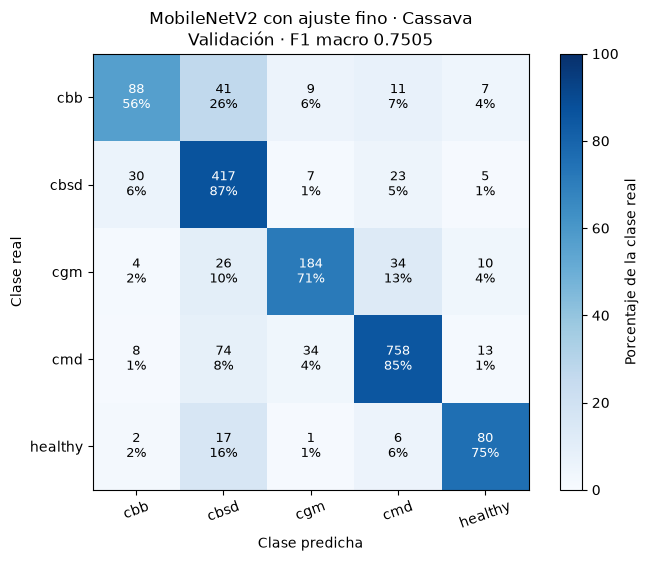

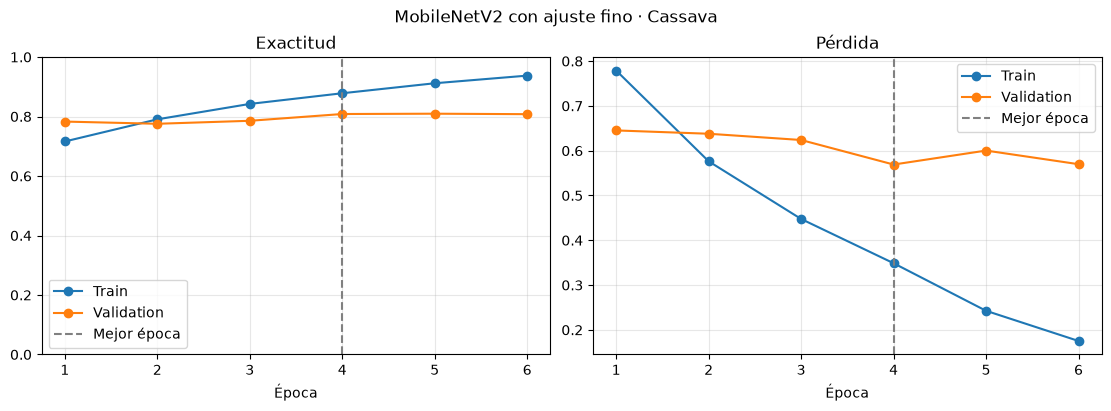

In [19]:
resumen_3 = evaluar(carpeta_ajuste, "MobileNetV2 con ajuste fino · Cassava")

In [12]:
from pathlib import Path
import json

# Detectar la carpeta de Cassava
carpeta_actual = Path.cwd()

if carpeta_actual.name.lower() == "cassava":
    carpeta_cassava = carpeta_actual
else:
    carpeta_cassava = carpeta_actual / "cassava"

# Ubicar los resultados de MobileNetV2
carpeta_resultados = (
    carpeta_cassava / "resultados" / "mobilenetv2"
)


# Carpetas originales de tus entrenamientos
carpeta_sin_ponderacion = carpeta_resultados / "corrida_20261117_041049_112297"
carpeta_moderada = carpeta_resultados / "ponderada_moderada_20261117_193118_439616"
carpeta_ajuste = carpeta_resultados / "ajuste_fino_20261117_205820_216835"

def recuperar(carpeta):
    ruta = carpeta / "metricas_validation.json"
    if not ruta.exists():
        raise FileNotFoundError(f"No se encontró: {ruta}")
    return json.loads(ruta.read_text(encoding="utf-8"))

resumen_1 = recuperar(carpeta_sin_ponderacion)
resumen_2 = recuperar(carpeta_moderada)
resumen_3 = recuperar(carpeta_ajuste)

clases = ["cbb", "cbsd", "cgm", "cmd", "healthy"]

print("¡Resultados recuperados!")
print("F1 Prueba 1:", resumen_1["f1_macro_validation"])
print("F1 Prueba 2:", resumen_2["f1_macro_validation"])
print("F1 Prueba 3:", resumen_3["f1_macro_validation"])

¡Resultados recuperados!
F1 Prueba 1: 0.6942
F1 Prueba 2: 0.6837
F1 Prueba 3: 0.7505


## Comparación de las corridas en Validation

In [10]:
# Tabla comparativa: la mejor corrida se selecciona por F1 macro en Validation.
resumenes = [resumen_1, resumen_2, resumen_3]
print(f"{'Corrida':<38} {'Exactitud':>10} {'F1 macro':>9}  "
      + "  ".join(f"{c:>8}" for c in clases))
for r in resumenes:
    print(f"{r['corrida']:<38} {r['exactitud_validation']:>10.2%} "
          f"{r['f1_macro_validation']:>9.4f}  "
          + "  ".join(f"{r['f1_por_clase'][c]:>8.4f}" for c in clases))
mejor = max(resumenes, key=lambda r: r["f1_macro_validation"])
print("\nMejor corrida de MobileNetV2 en Cassava:", mejor["corrida"])
(carpeta_resultados / "comparacion_corridas.json").write_text(
    json.dumps({"mejor": mejor["corrida"], "corridas": resumenes},
               indent=2, ensure_ascii=False),
    encoding="utf-8",
)

Corrida                                 Exactitud  F1 macro       cbb      cbsd       cgm       cmd   healthy
corrida_20261117_041049_112297             76.34%    0.6942    0.5799    0.7409    0.6523    0.8446    0.6533
ponderada_moderada_20261117_193118_439616     75.17%    0.6837    0.5752    0.7191    0.6400    0.8429    0.6412
ajuste_fino_20261117_205820_216835         80.84%    0.7505    0.6111    0.7890    0.7465    0.8819    0.7240

Mejor corrida de MobileNetV2 en Cassava: ajuste_fino_20261117_205820_216835


5133